<a href="https://colab.research.google.com/github/Hhvost/Algosy_2_sem/blob/Lab_1/%D0%9B%D0%B0%D0%B1%D0%B0_1_%D0%A6%D0%B8%D0%BA%D0%B0%D0%B4%D1%8B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №1. Тайна простых цикад

*Информатика, 1 семестр. Пройденные темы: командная строка Linux, базовый синтаксис Python, обработка последовательностей, системы счисления и обработка потока, полный перебор, списки.*
*Новое в этой работе: **файлы**, **функции** и библиотека **numpy**. Справки по новому даны прямо в тексте.*

**ФИО:** *Кузнецова Екатерина Алексеевна*

**Группа:** *Б06-506*

## Сюжет

Весной 2024 года на Среднем Западе США случилось событие, которого не было 221 год: из-под земли **одновременно** вышли два выводка периодических цикад — **выводок XIII** (живёт под землёй 17 лет) и **выводок XIX** (13 лет). Предыдущий раз так было в 1803 году, следующий будет в 2245-м.

Периодические цикады (род *Magicicada*) — одни из самых странных насекомых на Земле. Их личинки (нимфы) 13 или 17 лет сидят под землёй и питаются соком корней. А потом в один и тот же год, почти в один день, миллиарды взрослых насекомых выбираются на поверхность, несколько недель оглушительно поют, откладывают яйца и погибают. В годы вспышек на квадратный метр могут приходиться сотни нимф.

Биологов давно занимает вопрос: **почему 13 и 17?** Оба числа простые. Одна из гипотез: простой период плохо «синхронизируется» с циклами хищников и паразитов, у которых численность тоже колеблется с периодом в несколько лет. Если бы цикады выходили раз в 12 лет, их вспышки совпадали бы с пиками хищников с циклами 2, 3, 4, 6 и 12 лет. А при периоде 13 хищник с циклом от 2 до 12 лет совпадёт с цикадами лишь раз в 13·P лет. Гипотеза спорная, а экспериментом её проверять трудно: один опыт длится 17 лет. Зато её можно проверить **расчётом**.

Вы — участник экспедиции «Цикада». Вам достался архив с журналами 12 полевых станций за 1950–2025 годы и выписками из дневников натуралистов XIX века. Предстоит:

1. достать данные из архива — **командная строка Linux**;
2. прочитать журнал станции и посчитать статистику — **файлы, обработка потока**;
3. разобраться со «странными» записями: шестнадцатеричным логгером и римскими годами — **системы счисления, функции**;
4. по годам вспышек определить период и номер выводка для каждой станции — **списки, алгоритм Евклида**;
5. разгадать загадку станции, где период «не определяется», и проверить гипотезу о простых числах — **полный перебор**;
6. повторить расчёты в несколько строк и построить графики — **numpy**;
7. записать итоговый отчёт в файл.

> Данные в архиве учебные: числа смоделированы. Но выводки, их номера, периоды и годы выхода — настоящие.

## Как работать и как сдавать

- Задания отмечены **📝 Задание N.M (баллы)**. Код пишите в ячейках с пометкой `# ваш код`. В некоторых ячейках код уже написан: их нужно запустить и разобраться, что они делают.
- Справки по новым темам отмечены **📘**.
- Ячейки с `assert` — самопроверка. Если ячейка выполнилась без ошибки, проверки пройдены. Правильность всего решения это не гарантирует.
- Ответы на вопросы пишите в markdown-ячейках «**Ответ:** …» (двойной щелчок — редактировать, Shift+Enter — готово).
- **Перед сдачей:** *Kernel → Restart Kernel and Run All Cells* (в Colab: *Среда выполнения → Перезапустить и выполнить всё*). Ноутбук должен пройти сверху вниз без ошибок.
- Сдаётся файл `Лаба1_Фамилия_Группа.ipynb` и папка `results/` (заархивируйте её).

| Часть | Тема | Баллы |
|---|---|---|
| 1 | Командная строка Linux | 10 |
| 2 | Файлы и обработка потока | 15 |
| 3 | Системы счисления, функции | 15 |
| 4 | Списки, алгоритм Евклида | 20 |
| 5 | Полный перебор | 20 |
| 6 | numpy и графики | 15 |
| 7 | Итоговый отчёт | 5 |
| Б | Бонусные задания | +15 |
| | **Итого** | **100 (+15)** |

---
## Часть 0. Подготовка рабочего места

Понадобятся **Python 3.9 или новее**, **Jupyter** и библиотеки **numpy** и **matplotlib**. Выберите один вариант.

**Вариант А. Linux (компьютер в классе) или macOS.** В терминале:
```bash
python3 --version                    # должно быть 3.9 или больше
python3 -m venv ~/venvs/lab          # создать виртуальное окружение (один раз)
source ~/venvs/lab/bin/activate      # включить его (в каждом новом терминале)
pip install jupyterlab numpy matplotlib
cd ~/путь/к/папке/с/лабой            # папка, где лежат ноутбук и cicadas_data.zip
jupyter lab                          # откроется браузер
```
Если `python3 -m venv` ругается, в Ubuntu/Debian поставьте пакет `python3-venv` (`sudo apt install python3-venv`) или ставьте библиотеки без окружения: `pip install --user jupyterlab numpy matplotlib`.

**Вариант Б. Windows.**
- Проще всего поставить **Anaconda** (anaconda.com/download): Jupyter, numpy и matplotlib там уже есть. Запуск: меню Пуск → *Anaconda Prompt* → `cd` в папку с лабой → `jupyter lab`.
- Или Python с python.org (при установке отметьте *Add python.exe to PATH*), затем в PowerShell: `py -m pip install jupyterlab numpy matplotlib`, потом `py -m jupyter lab`.
- Можно работать в **VS Code** с расширениями *Python* и *Jupyter*: он открывает `.ipynb` сам, но библиотеки поставить всё равно нужно (`pip install ipykernel numpy matplotlib`).
- Для **части 1** нужна оболочка bash. В Windows её нет, варианты: WSL (в PowerShell от администратора `wsl --install`, перезагрузка), Git Bash (ставится вместе с Git for Windows), компьютер в классе или Colab.

**Вариант В. Google Colab** — ничего ставить не надо. colab.research.google.com → *Файл → Загрузить блокнот* → выберите этот `.ipynb`. Затем слева на панели «Файлы» загрузите `cicadas_data.zip`. Colab работает на Linux, поэтому ячейки `%%bash` из части 1 там работают. Минус: после закрытия сессии файлы удаляются, поэтому скачайте папку `results/` до ухода.

### Ноутбук за одну минуту
- Ноутбук состоит из ячеек: **код** (Code) и **текст** (Markdown).
- **Shift+Enter** — выполнить ячейку и перейти к следующей.
- Переменные живут между ячейками, пока работает **ядро** (kernel). Порядок выполнения важен: номер `[5]` слева показывает, какой по счёту запустилась ячейка.
- Если что-то «сломалось» и непонятно почему — *Restart Kernel* и выполнить всё заново сверху.
- Последнее выражение в ячейке печатается само, без `print`.

Положите `cicadas_data.zip` в одну папку с ноутбуком и запустите ячейку ниже: она проверит, что всё установлено.

In [58]:
import sys
print('Python', sys.version.split()[0])
assert sys.version_info >= (3, 9), 'Нужен Python 3.9 или новее'

import numpy as np
import matplotlib
print('numpy', np.__version__, '| matplotlib', matplotlib.__version__)

import os
print('Рабочая папка:', os.getcwd())
print('Архив рядом с ноутбуком:', os.path.exists('cicadas_data.zip'))

Python 3.13.18
numpy 2.4.6 | matplotlib 3.10.0
Рабочая папка: /content
Архив рядом с ноутбуком: True


---
## Часть 1. Распаковываем архив экспедиции (командная строка Linux) — 10 баллов

📘 **Справка: bash внутри ноутбука.** Ячейка, первая строка которой `%%bash`, выполняется не Python'ом, а оболочкой **bash** — так же, как если бы вы набрали команды в терминале. Важно: каждая такая ячейка запускает **новую** оболочку в папке ноутбука, поэтому `cd` из одной ячейки на следующую не действует. (Одну команду можно запустить и из обычной ячейки, поставив перед ней `!`, например `!ls -l`.)

Команды с первого занятия плюс несколько новых:

| Команда | Что делает |
|---|---|
| `pwd`, `ls -l`, `ls -R`, `cd`, `mkdir -p`, `cat`, `echo` | уже знакомы |
| `unzip -o архив.zip` | распаковать zip-архив в текущую папку; `-o` — перезаписывать файлы без вопросов (иначе при повторном запуске ячейка «повиснет» в ожидании ответа) |
| `head -n 5 файл` / `tail -n 5 файл` | первые / последние 5 строк файла |
| `wc -l файл` | число строк в файле (*word count*, `-l` — *lines*) |
| `ls папка/*.txt` | `*` — шаблон «любые символы»: bash сам подставит все подходящие имена файлов |
| `команда > файл`, `команда >> файл` | перенаправить вывод в файл (перезаписать / дописать в конец) |
| `команда1 \| команда2` | **конвейер** (pipe): вывод первой команды идёт на вход второй |

Пример конвейера: `ls папка | wc -l` — сколько файлов в папке. Подробности о любой команде: `man unzip`, `man wc` (в терминале; выход — `q`).

Если `unzip` не установлен, архив распакует сам Python: `python3 -m zipfile -e cicadas_data.zip .`

📝 **Задание 1.1 (3 балла).** Выведите путь к текущей папке и её подробное содержимое. Распакуйте архив `cicadas_data.zip` и выведите **рекурсивно** содержимое папки `cicadas_data`.

In [59]:
%%bash
# ваш код: pwd, ls -l, распаковка, рекурсивный ls
pwd
ls -l
unzip -o cicadas_data.zip
ls -lR cicadas_data

/content
total 24
drwxr-xr-x 4 root root 4096 Nov 24 17:22 cicadas_data
-rw-r--r-- 1 root root 8771 Nov 24 17:21 cicadas_data.zip
drwxr-xr-x 2 root root 4096 Nov 24 17:22 results
drwxr-xr-x 1 root root 4096 Nov 18 15:58 sample_data
Archive:  cicadas_data.zip
  inflating: cicadas_data/README.txt  
  inflating: cicadas_data/broods.txt  
  inflating: cicadas_data/stations/st01_springfield_il.txt  
  inflating: cicadas_data/stations/st02_chicago_il.txt  
  inflating: cicadas_data/stations/st03_bloomington_in.txt  
  inflating: cicadas_data/stations/st04_baltimore_md.txt  
  inflating: cicadas_data/stations/st05_louisville_ky.txt  
  inflating: cicadas_data/stations/st06_cape_cod_ma.txt  
  inflating: cicadas_data/stations/st07_atlanta_ga.txt  
  inflating: cicadas_data/stations/st08_st_louis_mo.txt  
  inflating: cicadas_data/stations/st09_little_rock_ar.txt  
  inflating: cicadas_data/stations/st10_baton_rouge_la.txt  
  inflating: cicadas_data/stations/st11_richmond_va.txt  
  inflating:

📝 **Задание 1.2 (4 балла).** Только командами bash выясните:

а) что написано в `cicadas_data/README.txt` (выведите его целиком — **прочитайте внимательно**, там описан формат данных);
б) первые 8 строк журнала станции Чикаго (`cicadas_data/stations/st02_chicago_il.txt`);
в) сколько файлов в папке `cicadas_data/stations` (конвейером `|`);
г) сколько строк в каждом журнале станции — одной командой `wc -l` с шаблоном `*`.

Чтобы вывод не сливался, разделяйте части командой вроде `echo '--- б) ---'`.

In [60]:
# ваш код
%%bash
echo '--- а) что написано ---'
cat cicadas_data/README.txt

echo '--- б) первые 8 строк журнала Чикаго ---'
head -n 8 cicadas_data/stations/st02_chicago_il.txt

echo '--- в) сколько файлов ---'
ls cicadas_data/stations | wc -l

echo '--- г) сколько строк в каждом журнале станци ---'
wc -l cicadas_data/stations/*.txt

--- а) что написано ---
ДАННЫЕ ЭКСПЕДИЦИИ «ЦИКАДА»

Учебный набор данных. Числа смоделированы, но устроены так же, как настоящие
наблюдения за периодическими цикадами (род Magicicada) в США.

Состав:
  README.txt               - этот файл
  broods.txt               - справочник выводков: номер (римскими цифрами), период, год последнего выхода
  stations/                - журналы полевых станций, по одному файлу на станцию
  archive/                 - выписки из дневников натуралистов XIX века

Журнал станции:
  строки, начинающиеся с '#', - комментарии;
  пустые строки пропускаются;
  остальные строки - "год;плотность", плотность = число нимф на квадратный метр;
  "н/д" - данных за этот год нет.

Вспышкой (массовым выходом) считается год с плотностью не меньше 50 нимф на кв. м.

Справочник broods.txt: если выводок с периодом p последний раз выходил в год Y,
то он выходит во все годы вида Y + k*p (k - целое, в том числе отрицательное).
--- б) первые 8 строк журнала Чикаго ---
# Полевая 

📝 **Задание 1.3 (3 балла).** Создайте папку `results` (ключ `-p` — чтобы не было ошибки, если она уже есть). Одной командой `cat` с шаблоном и перенаправлением склейте журналы всех станций в файл `results/all_stations.txt`. Выведите число строк в получившемся файле и его последние 3 строки.

Затем ответьте ниже: сколько станций в экспедиции? Совпадает ли число строк склеенного файла с итогом `total` из задания 1.2г? Почему?

In [61]:
%%bash
mkdir -p results
cat cicadas_data/stations/*.txt > results/all_stations.txt
wc -l results/all_stations.txt
tail -n 3 results/all_stations.txt

939 results/all_stations.txt
2023;2
2024;4
2025;2


**Ответ:** станций 12, число строк совпадает, потому что cat не менял файлы, просто склеил, соответственно и количество строк в файлах по отдельности не изменилось, также cat не добавляет новые строки. Поэтому, так как обращение было к одним и тем же файлам - формата ***.txt - и суммарное количество строк не изменилось

Страховочная ячейка ниже нужна, если часть 1 не получилась (например, в Windows нет bash). Она распакует архив средствами Python. Если архив уже распакован, она ничего не тронет.

In [62]:
import os
import zipfile

if not os.path.exists('cicadas_data'):
    with zipfile.ZipFile('cicadas_data.zip') as z:
        z.extractall('.')
    print('Архив распакован средствами Python')
os.makedirs('results', exist_ok=True)          # то же, что mkdir -p results
print(sorted(os.listdir('cicadas_data/stations')))

['st01_springfield_il.txt', 'st02_chicago_il.txt', 'st03_bloomington_in.txt', 'st04_baltimore_md.txt', 'st05_louisville_ky.txt', 'st06_cape_cod_ma.txt', 'st07_atlanta_ga.txt', 'st08_st_louis_mo.txt', 'st09_little_rock_ar.txt', 'st10_baton_rouge_la.txt', 'st11_richmond_va.txt', 'st12_wheeling_wv.txt']


---
## Часть 2. Читаем журнал станции (файлы + обработка потока) — 15 баллов

📘 **Справка: текстовые файлы в Python.**

Файл открывают функцией `open(путь, режим, encoding='utf-8')`. Режимы: `'r'` — чтение (по умолчанию), `'w'` — запись (файл создаётся заново, **старое содержимое стирается**), `'a'` — дописывание в конец (как `>>` в bash).

Открывать файл правильно через `with`: файл закроется сам, когда блок закончится, даже если внутри случилась ошибка.
```python
with open('cicadas_data/README.txt', encoding='utf-8') as f:
    text = f.read()          # весь файл одной строкой
print(text)
```

Чаще всего файл удобнее читать **построчно** — циклом `for` прямо по файлу. Это та самая **обработка потока**: файл может весить хоть 10 ГБ, а в памяти одновременно лежит одна строка.
```python
with open('cicadas_data/broods.txt', encoding='utf-8') as f:
    for line in f:
        line = line.strip()                  # убрать '\n' в конце и пробелы по краям
        if line == '' or line.startswith('#'):
            continue                         # пропустить пустые строки и комментарии
        parts = line.split(';')              # 'X;17;2021' -> ['X', '17', '2021']
        print(parts)
```

Запись:
```python
with open('results/hello.txt', 'w', encoding='utf-8') as f:
    f.write('Первая строка\n')         # write НЕ добавляет перевод строки сам
    print('Вторая строка', file=f)    # print умеет печатать в файл (и сам ставит '\n')
```

Можно открыть два файла сразу — один читать, в другой писать:
```python
with open('вход.txt', encoding='utf-8') as fin, open('выход.txt', 'w', encoding='utf-8') as fout:
    for line in fin:
        ...
```

- Пути вида `cicadas_data/...` — **относительные**: они отсчитываются от рабочей папки (её печатает `os.getcwd()`; вспомните `pwd` из части 1).
- Всегда указывайте `encoding='utf-8'`. Иначе в Windows русский текст прочитается «кракозябрами» или с ошибкой `UnicodeDecodeError`.
- Строка, прочитанная из файла, — это **строка** (`str`), даже если в ней число: `'1956'`. Не забывайте `int(...)`.

Запустите пример:

In [63]:
with open('cicadas_data/broods.txt', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if line == '' or line.startswith('#'):
            continue
        parts = line.split(';')
        print(parts)

['I', '17', '2012']
['II', '17', '2013']
['III', '17', '2014']
['IV', '17', '2015']
['V', '17', '2016']
['VI', '17', '2017']
['VII', '17', '2018']
['VIII', '17', '2019']
['IX', '17', '2020']
['X', '17', '2021']
['XIII', '17', '2024']
['XIV', '17', '2025']
['XIX', '13', '2024']
['XXII', '13', '2014']
['XXIII', '13', '2015']


📝 **Задание 2.1 (5 баллов).** Прочитайте журнал станции Чикаго `cicadas_data/stations/st02_chicago_il.txt` **за один проход и не сохраняя данные в список**. Посчитайте:

- число лет с данными и число лет с пропуском (`н/д`);
- среднюю плотность по годам с данными (два знака после запятой);
- максимальную плотность и год, когда она была;
- **вторую по величине** плотность и её год. Это значение из другого года; если максимум встречается дважды, второе значение равно первому.

Подсказка: поиск двух максимумов за один проход разбирали на занятии «Сложная обработка потока».

In [64]:
path = 'cicadas_data/stations/st02_chicago_il.txt'
n_data = 0
n_missing = 0
max_density = float(-1)
max_dens_year = None
sec_density = float(-1)
sec_dens_year = None
total = 0.0

with open(path, encoding='utf-8') as f:
    for line in f:
        line = line.strip()

        if not line or line.startswith('#'):
            continue

        parts = line.split(';')
        if len(parts) < 2:
            continue
        year = parts[0].strip()
        density = parts[1].strip()

        if density == 'н/д':
            n_missing += 1
            continue
        x = float(density)
        n_data += 1
        total += x

        if x > max_density:
            sec_density, sec_dens_year = max_density, max_dens_year
            max_density, max_dens_year = x, year
        elif x > sec_density:
            sec_density, sec_dens_year = x, year

print(f'''Лет с данными: {n_data}
Лет с пропуском: {n_missing}
Средняя плотность: {(total / n_data):.2f}
Максимальная плотность: {max_density} (в {max_dens_year} году)
Вторая по величине плотность: {sec_density} (в {sec_dens_year} году)''')


Лет с данными: 73
Лет с пропуском: 1
Средняя плотность: 19.56
Максимальная плотность: 398.0 (в 2024 году)
Вторая по величине плотность: 332.0 (в 1973 году)


📝 **Задание 2.2 (5 баллов).** **Вспышки.** В README сказано, что вспышка — это год с плотностью не меньше 50. Снова пройдите по журналу Чикаго, не сохраняя данные. Выведите годы вспышек, а для каждой вспышки, начиная со второй, — сколько лет прошло с предыдущей. В конце выведите число вспышек.

Подсказка: нужна переменная «год предыдущей вспышки». Чем её инициализировать, чтобы отличить «предыдущей вспышки ещё не было»?

In [65]:
path = 'cicadas_data/stations/st02_chicago_il.txt'
THRESHOLD = 50
n_flashes = 0
prev_flash_year = None

with open(path, encoding='utf-8') as f:
    for line in f:
        line = line.strip()

        if not line or line.startswith('#'):
            continue

        parts = line.split(';')
        if len(parts) < 2:
            continue

        year = parts[0].strip()
        density = parts[1].strip()

        if density == 'н/д':
            continue

        x = float(density)
        if x >= 50:
            n_flashes += 1

            if prev_flash_year is None:
                print(f'1 вспышка: {year} - плотность {x}')
            else:
                gap = int(year) - int(prev_flash_year)
                print(f'{n_flashes} вспышка в: {year} (плотность {x}), прошло лет с предыдущей: {gap}')

            prev_flash_year = year

print(f"Всего вспышек: {n_flashes}")

1 вспышка: 1956 - плотность 162.0
2 вспышка в: 1973 (плотность 332.0), прошло лет с предыдущей: 17
3 вспышка в: 1990 (плотность 260.0), прошло лет с предыдущей: 17
4 вспышка в: 2007 (плотность 149.0), прошло лет с предыдущей: 17
5 вспышка в: 2024 (плотность 398.0), прошло лет с предыдущей: 17
Всего вспышек: 5


**Вопрос:** что вы заметили в интервалах между вспышками? Какой у этой станции период?

**Ответ:** интервалы между вспышками совпадают и равны 17, период 17

📝 **Задание 2.3 (5 баллов).** **Чистый журнал.** Перепишите данные Чикаго в файл `results/st02_clean.csv` в формате CSV: первая строка — заголовок `year,density`, дальше строки вида `1952,0`. Годы с пропусками и комментарии в чистый файл не попадают. Откройте два файла в одном `with`, как в справке.

Затем откройте получившийся файл ещё раз и выведите **первые 5 строк** (нужен счётчик строк) и общее число строк.

> CSV (*comma-separated values*) — самый простой табличный формат. Его открывают Excel, LibreOffice и библиотека pandas. Наш журнал — почти CSV, только с разделителем `;`, комментариями и «н/д».

In [66]:
src = 'cicadas_data/stations/st02_chicago_il.txt'
dst = 'results/st02_clean.csv'

with open(src, encoding='utf-8') as fin, open(dst, 'w', encoding='utf-8', newline='') as fout:

    fout.write('year,density\n')

    for line in fin:
        line = line.strip()

        if not line or line.startswith('#'):
            continue

        parts = line.split(';')
        if len(parts) < 2:
            continue

        year = parts[0].strip()
        raw  = parts[1].strip()
        if raw == 'н/д':
            continue

        fout.write(f'{year},{raw}\n')

with open(dst, encoding='utf-8') as f:
    n = 0
    for line in f:
        n += 1
        if n <= 5:
            print(line.rstrip('\n'))

print(f'Всего строк в файле: {n}')

year,density
1952,22
1953,0
1954,1
1955,0
Всего строк в файле: 74


---
## Часть 3. Странные записи: шестнадцатеричный логгер и римские годы — 15 баллов

📘 **Справка: функции.** Функция — именованный кусок кода, который можно вызывать много раз с разными данными. Вы уже пользуетесь чужими функциями: `print`, `len`, `int`. Свою функцию объявляют словом `def`:
```python
def digit_sum(n):
    """Сумма цифр натурального числа n."""     # строка-описание, необязательна
    s = 0
    while n > 0:
        s += n % 10
        n //= 10
    return s            # результат; на return функция сразу заканчивается

print(digit_sum(1803))          # 12
x = digit_sum(2024) * 2         # результат можно использовать в выражениях
```
- `n` — **параметр**: при вызове `digit_sum(1803)` он получает значение 1803.
- Переменные, созданные внутри функции (`s`), снаружи не видны. А вот переменные, созданные в ноутбуке снаружи, функция **читать** может.
- Функция без `return` возвращает `None`.
- Можно вернуть несколько значений через запятую: `return a, b`, а при вызове — `x, y = f(...)`.
- Функцию сначала объявляют (запускают ячейку с `def`), потом вызывают.

Запустите пример:

In [67]:
def digit_sum(n):
    """Сумма цифр натурального числа n."""
    s = 0
    while n > 0:
        s += n % 10
        n //= 10
    return s

print(digit_sum(1803), digit_sum(2024))

12 8


### 3.1. Станция Атланта

Посмотрим на начало журнала станции Атланта (`st07`). Ячейка ниже — аналог `head -n 12` на Python.

In [68]:
with open('cicadas_data/stations/st07_atlanta_ga.txt', encoding='utf-8') as f:
    n = 0
    for line in f:
        print(line, end='')
        n += 1
        if n == 12:
            break

# Полевая станция: Атланта, Джорджия
# Код станции: st07
# Метод: ловушки для выползающих нимф, среднее по 20 площадкам
# Формат строки: год;плотность (нимф на кв. метр); н/д = нет данных
# С 1958 г. учёт ведёт автоматический логгер ЛГ-16
1958;0x0
1959;0x106
1960;0x0
1961;0x0
1962;0x0
1963;0x0
1964;0x4


Ваш код из 2.1 на этом файле упадёт. Запустите ячейку ниже и прочитайте сообщение об ошибке. Потом **закомментируйте** строку (`Ctrl+/` или `#` в начале), чтобы ноутбук выполнялся целиком.

In [69]:
#int('0x10e')

📘 **Напоминание.** `int(s, 16)` переводит строку из 16-й системы (`'10e'` и `'0x10e'` — обе подходят), `int(s, 2)` — из двоичной. Обратно: `hex(270)` → `'0x10e'`, `bin(270)` → `'0b100001110'`. Префиксы `0x`, `0b`, `0o` — стандартная запись 16-, 2- и 8-ричных чисел в Python и во многих других языках.

📝 **Задание 3.1 (4 балла).** Напишите функцию `parse_density(s)`. Она получает строку-значение из журнала (например `'273'`, `'0x111'` или `'н/д'`) и возвращает целое число или `None`, если данных нет. Строки, начинающиеся с `'0x'`, считайте шестнадцатеричными. Ячейка с проверками должна выполниться без ошибок.

In [70]:
def parse_density(s):
    """'273' -> 273, '0x111' -> 273, 'н/д' -> None."""
    if s == 'н/д':
      return None
    elif s[0:2] == '0x':
      return int(s, 16)
    return int(s)

In [71]:
assert parse_density('273') == 273
assert parse_density('0x111') == 273
assert parse_density('0x0') == 0
assert parse_density('н/д') is None
print('parse_density: все проверки пройдены')

parse_density: все проверки пройдены


📝 **Задание 3.2 (3 балла).** С помощью `parse_density` пройдите по журналу Атланты и найдите максимальную плотность и её год, а также все годы вспышек (≥ 50). Максимум выведите в трёх системах: десятичной, шестнадцатеричной и двоичной. Сколько двоичных разрядов (битов) нужно, чтобы записать этот максимум?

In [72]:
path = 'cicadas_data/stations/st07_atlanta_ga.txt'

max_density = None
max_year = None
flash_years = []

with open(path, encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = line.split(';')
        if len(parts) < 2:
            continue

        year = parts[0].strip()
        x = parse_density(parts[1])
        if x is None:
            continue

        if (max_density is None) or (x > max_density):
            max_density = x
            max_year = year

        if x >= 50:
            flash_years.append(year)

print(f'''Максимумальная плотность = {max_density} (в {max_year} году)
  десятичная: {max_density}
  шестнадцатеричная: {hex(max_density)}
  двоичная: {bin(max_density)}''')

print('Годы вспышек:', *flash_years, f', всего - {len(flash_years)}')

Максимумальная плотность = 412 (в 2011 году)
  десятичная: 412
  шестнадцатеричная: 0x19c
  двоичная: 0b110011100
Годы вспышек: 1959 1972 1985 1998 2011 2024 , всего - 6


### 3.3. Римские цифры

Номера выводков (XIII, XIX, …) пишут римскими цифрами. Так их в начале XX века пронумеровал энтомолог Ч. Марлатт: номера I–XVII достались 17-летним выводкам, XVIII–XXX — 13-летним. В дневниках XIX века римскими цифрами записаны ещё и **годы**.

📘 **Напоминание.** Римская система — **непозиционная**: I = 1, V = 5, X = 10, L = 50, C = 100, D = 500, M = 1000. Значения цифр складываются, но если меньшая цифра стоит **перед** большей, она вычитается: IV = 4, XC = 90, MCMXC = 1000 + (1000 − 100) + (100 − 10) = 1990.

Ниже дана готовая функция `roman_digit` — значение одной римской цифры. Метод строки `s.index(ch)` возвращает номер позиции символа `ch` в строке `s`.

In [73]:
ROMAN_LETTERS = 'IVXLCDM'
ROMAN_VALUES = [1, 5, 10, 50, 100, 500, 1000]

def roman_digit(ch):
    """Значение одной римской цифры: 'X' -> 10."""
    return ROMAN_VALUES[ROMAN_LETTERS.index(ch)]

print(roman_digit('I'), roman_digit('X'), roman_digit('M'))

1 10 1000


📝 **Задание 3.3 (5 баллов).** По образцу напишите функцию `roman_to_int(s)`: римская запись → целое число. Пройдите по цифрам слева направо. Если значение текущей цифры меньше значения следующей, его нужно вычесть, иначе — прибавить.

In [74]:
def roman_to_int(s):
    """'MDCCCIII' -> 1803."""
    ROMAN_LETTERS = 'IVXLCDM'
    ROMAN_VALUES = [1, 5, 10, 50, 100, 500, 1000]
    total = 0
    for i in range(len(s) - 1):
      if ROMAN_LETTERS.index(s[i]) < ROMAN_LETTERS.index(s[i+1]):
        total -= ROMAN_VALUES[ROMAN_LETTERS.index(s[i])]
      else:
         total += ROMAN_VALUES[ROMAN_LETTERS.index(s[i])]
    total += ROMAN_VALUES[ROMAN_LETTERS.index(s[-1])]
    return total

In [75]:
assert roman_to_int('XIII') == 13
assert roman_to_int('XIX') == 19
assert roman_to_int('IV') == 4
assert roman_to_int('MCMXC') == 1990
assert roman_to_int('MMXXIV') == 2024
assert roman_to_int('MDCCCIII') == 1803
print('roman_to_int: все проверки пройдены')

roman_to_int: все проверки пройдены


📝 **Задание 3.4 (3 балла).** Прочитайте архив `cicadas_data/archive/archive_1800s.txt` (формат описан в его комментариях). Для каждой записи выведите строку вида `1803  выводок XIII (№13)  Иллинойс` — год и номер выводка арабскими цифрами. В конце выведите число записей, самую раннюю и самую позднюю дату.

In [76]:
%%bash
head -n 5 cicadas_data/archive/archive_1800s.txt

# Выписки из полевых дневников XIX века (оцифровка; учебные данные)
# Год в дневниках записан римскими цифрами.
# Формат: год;выводок;штат
MDCCCIII;XIII;Иллинойс
MDCCCIII;XIX;Иллинойс


In [77]:
path = 'cicadas_data/archive/archive_1800s.txt'

n_records = 0
min_year = None
max_year = None

with open(path, encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'):
            continue

        parts = line.split(';')
        if len(parts) < 3:
            continue

        year = roman_to_int(parts[0].strip())
        brood_roman = parts[1].strip()
        state = parts[2].strip()
        brood = roman_to_int(brood_roman)

        n_records += 1

        if min_year is None or year < min_year:
            min_year = year
        if max_year is None or year > max_year:
            max_year = year

        print(f"{year} выводок {brood_roman} (№{brood}) {state}")

print(f'''Всего записей: {n_records}
Самая ранняя в {min_year}
Самая поздняя в {max_year}''')

1803 выводок XIII (№13) Иллинойс
1803 выводок XIX (№19) Иллинойс
1817 выводок X (№10) Индиана
1821 выводок XIV (№14) Кентукки
1826 выводок II (№2) Виргиния
1833 выводок XXIII (№23) Арканзас
1838 выводок XIV (№14) Кентукки
1846 выводок XXIII (№23) Арканзас
1851 выводок X (№10) Мэриленд
1855 выводок XIV (№14) Кентукки
1860 выводок II (№2) Виргиния
1868 выводок XIX (№19) Миссури
1869 выводок X (№10) Индиана
1871 выводок XIII (№13) Иллинойс
1872 выводок XXIII (№23) Арканзас
1877 выводок II (№2) Виргиния
1881 выводок XIX (№19) Иллинойс
1888 выводок XIII (№13) Иллинойс
Всего записей: 18
Самая ранняя в 1803
Самая поздняя в 1888


---
## Часть 4. Все станции сразу: списки и алгоритм Евклида — 20 баллов

Пора обработать все 12 станций. Читать каждую вручную долго, поэтому дана готовая функция `read_station`. Она читает журнал целиком и возвращает **название станции и два списка** — годы и плотности (годы с пропусками пропускаются). Внутри используется ваша `parse_density`. Разберитесь, как она устроена: в ней нет ничего, чего вы ещё не писали сами.

📘 `os.listdir(папка)` — список имён файлов в папке, аналог `ls`. Порядок не гарантирован, поэтому оборачиваем в `sorted(...)`.

In [78]:
import os

def read_station(path):
    """Читает журнал станции. Возвращает (название, годы, плотности); годы с 'н/д' пропускаются."""
    name = ''
    years = []
    values = []
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line.startswith('# Полевая станция:'):
                name = line.split(':')[1].strip()
            if line == '' or line.startswith('#'):
                continue
            year, s = line.split(';')
            value = parse_density(s)
            if value is not None:
                years.append(int(year))
                values.append(value)
    return name, years, values


FOLDER = 'cicadas_data/stations'
files = sorted(os.listdir(FOLDER))
paths = [FOLDER + '/' + fn for fn in files]
print(files)

name, years, values = read_station(paths[1])
print(name, '| лет:', len(years), '| первые 5 записей:', years[:5], values[:5])

['st01_springfield_il.txt', 'st02_chicago_il.txt', 'st03_bloomington_in.txt', 'st04_baltimore_md.txt', 'st05_louisville_ky.txt', 'st06_cape_cod_ma.txt', 'st07_atlanta_ga.txt', 'st08_st_louis_mo.txt', 'st09_little_rock_ar.txt', 'st10_baton_rouge_la.txt', 'st11_richmond_va.txt', 'st12_wheeling_wv.txt']
Чикаго, Иллинойс | лет: 73 | первые 5 записей: [1952, 1953, 1954, 1955, 1956] [22, 0, 1, 0, 162]


📝 **Задание 4.1 (4 балла).** Напишите две функции:
- `emergence_years(years, values)` — список лет, в которые плотность была не меньше 50 (вспышки);
- `differences(a)` — список разностей соседних элементов: `[a[1]-a[0], a[2]-a[1], ...]`. Для списка из одного элемента — пустой список.

In [88]:
def emergence_years(years, values):
    flash_years = []
    for j in range(len(values)):
      if values[j] >= 50:
        flash_years.append(years[j])
    return flash_years

def differences(a):
    diff = []
    for i in range(len(a) - 1):
      diff.append(a[i+1] - a[i])
    return diff

In [89]:
assert emergence_years([2000, 2001, 2002, 2003], [3, 70, 50, 49]) == [2001, 2002]
assert emergence_years([1990], [10]) == []
assert differences([1956, 1973, 2007]) == [17, 34]
assert differences([5]) == []
print('emergence_years, differences: все проверки пройдены')

emergence_years, differences: все проверки пройдены


📝 **Задание 4.2 (4 балла).** Алгоритм Евклида. Напишите `gcd(a, b)` — НОД двух чисел через остатки от деления (как на занятии; `math.gcd` не использовать). Затем напишите `gcd_list(nums)` — НОД всех чисел списка. Подсказки: НОД(a, b, c) = НОД(НОД(a, b), c), а НОД(0, a) = a, так что начать можно с нуля.

In [90]:
def gcd(a, b):
    while b != 0:
        a, b = b, a % b
    return a


def gcd_list(nums):
    result = 0
    for x in nums:
        result = gcd(result, x)
    return result

In [91]:
assert gcd(17, 34) == 17
assert gcd(13, 17) == 1
assert gcd(0, 26) == 26
assert gcd_list([34, 17, 51]) == 17
assert gcd_list([26, 13]) == 13
assert gcd_list([]) == 0
print('gcd, gcd_list: все проверки пройдены')

gcd, gcd_list: все проверки пройдены


**Вопрос:** зачем брать НОД **всех** разностей, а не просто первую разность между вспышками? Какие «неприятности» в данных это обходит? (Вспомните README и подумайте про `н/д`.)

**Ответ:** *напишите здесь*

📝 **Задание 4.3 (6 баллов).** Для каждой станции из `paths`: прочитайте журнал, найдите годы вспышек, их разности и **период** = НОД разностей. Соберите всё в **список списков** `table`, по строке на станцию:

`[код, название, число_лет_с_данными, максимальная_плотность, список_лет_вспышек, период]`

Код станции — первые 4 символа имени файла (`'st01'`). Выведите таблицу ровными столбцами. Пример форматирования: `f'{code:<6}{name:<28}{n:>5}'` — `<` выравнивает влево, `>` вправо, число — ширина поля.

Какая станция выглядит странно?

In [98]:
table = []
FOLDER = 'cicadas_data/stations'
files = sorted(os.listdir(FOLDER))
paths = [FOLDER + '/' + fn for fn in files]

import os

for path in paths:
    name, years, values = read_station(path)
    flash_years = emergence_years(years, values)
    diffs = differences(flash_years)
    period = gcd_list(diffs)
    code = os.path.basename(path)[:4]
    n_years = len(years)
    max_density = max(values) if values else None

    table.append([code, name, n_years, max_density, flash_years, period])

print(f"{'code':<6}{'name':<28}{'n':>5}{'max':>6}  {'flashes':<40}{'period':>7}")
print('-' * 95)
for row in table:
    code, name, n_years, max_density, flash_years, period = row
    flashes_str = ', '.join(map(str, flash_years)) if flash_years else '—'
    print(f"{code:<6}{name:<28}{n_years:>5}{max_density:>6}  {flashes_str:<40}{period:>7}")

code  name                            n   max  flashes                                  period
-----------------------------------------------------------------------------------------------
st01  Спрингфилд, Иллинойс           76   357  1956, 1959, 1972, 1973, 1985, 1990, 1998, 2007, 2011, 2024      1
st02  Чикаго, Иллинойс               73   398  1956, 1973, 1990, 2007, 2024                 17
st03  Блумингтон, Индиана            73   408  1953, 1970, 2004, 2021                       17
st04  Балтимор, Мэриленд             66   420  1970, 1987, 2004, 2021                       17
st05  Луисвилл, Кентукки             71   322  1957, 1974, 1991, 2008, 2025                 17
st06  Кейп-Код, Массачусетс          63   298  1974, 1991, 2008, 2025                       17
st07  Атланта, Джорджия              65   412  1959, 1972, 1985, 1998, 2011, 2024           13
st08  Сент-Луис, Миссури             73   402  1959, 1972, 1985, 1998, 2011, 2024           13
st09  Литл-Рок, Арканзас       

**Ответ:** странно выглядит первая станция - Спрингфилд, Иллинойс

📝 **Задание 4.4 (3 балла).** Прочитайте справочник `cicadas_data/broods.txt` в три списка: `brood_names` (строки), `brood_periods` и `brood_last` (целые). Напишите функцию `find_brood(period, year)`. Она возвращает название выводка, у которого такой период и который выходит в год `year`, или `'?'`, если такого нет. Выводок выходит в год `year`, если `(последний_выход - year) % период == 0` (см. README).

Добавьте название выводка в конец каждой строки `table` (по первой вспышке станции) и выведите пары «станция — выводок».

In [99]:
brood_names, brood_periods, brood_last = [], [], []

with open('cicadas_data/broods.txt', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = line.split(';')
        if len(parts) < 3:
            continue

        name   = parts[0].strip()
        period = int(parts[1].strip())
        last   = int(parts[2].strip())

        brood_names.append(name)
        brood_periods.append(period)
        brood_last.append(last)

def find_brood(period, year):
    for i in range(len(brood_names)):
        if brood_periods[i] == period and (year - brood_last[i]) % period == 0:
            return brood_names[i]
    return '?'


for row in table:
    flash_years = row[4]
    period      = row[5]
    first_year  = flash_years[0] if flash_years else None
    brood       = find_brood(period, first_year) if (first_year is not None and period) else None
    row.append(brood)

print(f"{'code':<6}{'name':<28}{'n':>5}{'max':>6}  {'flashes':<40}{'period':>7}  {'brood':<14}")
print('-' * 112)

for row in table:
    code, name, n_years, max_density, flash_years, period, brood = row

    flashes_str = ', '.join(map(str, flash_years)) if flash_years else '—'
    brood_str   = brood if brood is not None else '—'
    max_str     = f"{max_density:>6}" if max_density is not None else f"{'—':>6}"

    print(f"{code:<6}{name:<28}{n_years:>5}{max_str}  "
          f"{flashes_str:<40}{str(period) if period is not None else '—':>7}  "
          f"{brood_str:<14}")

print()
print('Пары «станция — выводок»:')
for row in table:
    code, name, n_years, max_density, flash_years, period, brood = row
    brood_str = brood if brood is not None else '—'
    print(f"{name} ({code}) — {brood_str}")

code  name                            n   max  flashes                                  period  brood         
----------------------------------------------------------------------------------------------------------------
st01  Спрингфилд, Иллинойс           76   357  1956, 1959, 1972, 1973, 1985, 1990, 1998, 2007, 2011, 2024      1  ?             
st02  Чикаго, Иллинойс               73   398  1956, 1973, 1990, 2007, 2024                 17  XIII          
st03  Блумингтон, Индиана            73   408  1953, 1970, 2004, 2021                       17  X             
st04  Балтимор, Мэриленд             66   420  1970, 1987, 2004, 2021                       17  X             
st05  Луисвилл, Кентукки             71   322  1957, 1974, 1991, 2008, 2025                 17  XIV           
st06  Кейп-Код, Массачусетс          63   298  1974, 1991, 2008, 2025                       17  XIV           
st07  Атланта, Джорджия              65   412  1959, 1972, 1985, 1998, 2011, 2024           

📝 **Задание 4.5 (3 балла).** **Проверка архива.** Для каждой записи из архива XIX века (файл из 3.4) проверьте по справочнику, мог ли указанный выводок выйти в указанный год. Выведите записи, которые **не сходятся**. Для каждой такой записи найдите ближайший год (раньше или позже), когда этот выводок действительно выходил: видимо, переписчик ошибся.

Подсказка: номер выводка в списке `brood_names` даёт `brood_names.index(brood)`.

In [110]:
ARCHIVE = 'cicadas_data/archive/archive_1800s.txt'

records = []
with open(ARCHIVE, encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        parts = line.split(';')
        if len(parts) < 3:
            continue
        year        = roman_to_int(parts[0].strip())
        brood_field = parts[1].strip()      # 'XIII', 'XIX'
        state       = parts[2].strip()
        records.append((year, brood_field, state))

print('Записи, которые не сходятся:')

bad_count = 0
for year, brood_field, state in records:
    id = brood_names.index(brood_field)

    period = brood_periods[id]
    last   = brood_last[id]
    found = find_brood(period, year)

    if found != '?':
        continue
    if not period:
        continue

    print(f'{year} {brood_field} {state}')
    bad_count += 1

print(f'Всего записей {len(records)}, не сходится {bad_count}')

Записи, которые не сходятся:
1869 X Индиана
Всего записей 18, не сходится 1


**Ответ:** 1868 год, на год раньше

---
## Часть 5. Полный перебор: загадка Спрингфилда и гипотеза простых чисел — 20 баллов

📝 **Задание 5.1 (5 баллов).** **Загадка Спрингфилда.** У станции st01 период получился 1. Выведите её годы вспышек. Гипотеза: на этой территории живут **два** выводка с разными периодами.

Если выводок выходит раз в `p` лет, то у всех его лет выхода **одинаковый остаток** `r = год % p`. Полным перебором всех `p` от 10 до 20 и всех остатков `r` от 0 до `p - 1` посчитайте, сколько лет вспышек дают остаток `r` при делении на `p`. Выведите пары `(p, r)`, которые объясняют **не меньше 4** вспышек.

Затем:
- для найденных пар определите выводки через `find_brood` (подставьте любой год вспышки этой пары);
- проверьте, что каждый год вспышки объясняется хотя бы одной из двух пар, и найдите год, который объясняется **обеими**.

In [ ]:
sp = table[0]                  # st01, Спрингфилд
sp_years = sp[4]
print(sp[1], sp_years)
# ваш код: перебор p и r

# ваш код: проверка, что все годы объяснены

**Ответ:** *напишите здесь*

📝 **Задание 5.2 (4 балла).** **Простые числа.** Ниже дана функция `divisors(n)` — список всех делителей перебором. По образцу напишите `is_prime(n)`: проверку на простоту перебором делителей от 2, пока `d * d <= n`. Почему достаточно дойти до корня? Затем выведите таблицу для всех `n` от 10 до 20: число, простое ли, делители.

In [ ]:
def divisors(n):
    """Все делители натурального n (полный перебор)."""
    result = []
    for d in range(1, n + 1):
        if n % d == 0:
            result.append(d)
    return result

print(divisors(12), divisors(13))

In [ ]:
def is_prime(n):
    # ваш код
    pass


# ваш код: таблица для n от 10 до 20

In [ ]:
assert [n for n in range(30) if is_prime(n)] == [2, 3, 5, 7, 11, 13, 17, 19, 23, 29]
assert is_prime(221) is False
print('is_prime: все проверки пройдены')

**Ответ:** *напишите здесь*

📝 **Задание 5.3 (6 баллов).** **Модель «цикада против хищника».** Пусть численность хищника (птиц, паразитических ос, грибков) достигает пика каждые `P` лет, `P` от 2 до 10, а цикада выходит каждые `C` лет, `C` от 10 до 20. Для простоты оба цикла начинаются в год 0. **Неудачный год** для цикады — год, когда она выходит одновременно с пиком хищника, то есть год делится и на `C`, и на `P`.

Полным перебором лет от 1 до 1000 посчитайте для каждого `C` **суммарное** число неудачных лет по всем хищникам `P = 2..10`. Сохраните результаты в список `bad`: `bad[0]` — для `C = 10`, `bad[1]` — для `C = 11`, … Выведите таблицу: `C`, простое ли, число неудачных лет. Найдите лучший `C`.

In [ ]:
N_YEARS = 1000
C_RANGE = range(10, 21)
P_RANGE = range(2, 11)

bad = []
# ваш код

**Вопросы:** какой `C` лучше всех? Как ведут себя простые и составные `C`? Почему у составных, например у 12 и 18, неудачных лет так много? Почему в природе, по-вашему, не 19, хотя в модели оно лучше 17? (Подумайте, чем опасны лишние годы под землёй.)

**Ответ:** *напишите здесь*

📝 **Задание 5.4 (5 баллов).** **Когда встретятся снова?**

а) Напишите функцию `factorize(n)` — разложение на простые множители перебором (список множителей). Разложите 221.

б) Перебором по годам (цикл `while`, начиная с 2025 вверх) найдите ближайший год, когда **одновременно** выйдут выводки XIII и XIX. Затем перебором вниз от 2023 найдите предыдущий такой год. Есть ли этот год в архиве XIX века?

в) Для **каждой пары** выводков из справочника с **разными** периодами найдите ближайший год их совместного выхода, начиная с 2025. Какая пара встретится раньше всех?

In [81]:
def factorize(n):
    # ваш код
    pass

print('а) 221 =', factorize(221))

# б) ваш код

# в) ваш код

а) 221 = None


**Ответ:** *напишите здесь*

---
## Часть 6. То же самое — короче и быстрее: numpy — 15 баллов

📘 **Справка: numpy.** Это главная библиотека Python для работы с массивами чисел. На ней построены почти все научные пакеты: pandas, scipy, scikit-learn, matplotlib, а также библиотеки для обработки изображений, сигналов и последовательностей ДНК.

**Чем массив отличается от списка.** Список Python может хранить что угодно вперемешку. Массив numpy (`ndarray`) хранит числа **одного типа** подряд в памяти. Операции над всем массивом выполняются скомпилированным кодом на C — обычно в десятки и сотни раз быстрее, чем цикл `for` на Python. Подход «пишем операцию сразу над всем массивом, без цикла» называется **векторизацией**.

```python
import numpy as np                    # общепринятое сокращение

a = np.array([3, 70, 50, 49])         # из списка
r = np.arange(10, 21)                 # как range: 10, 11, ..., 20
z = np.zeros(5)                       # пять нулей (тип float)
a.dtype, a.shape, len(a)              # тип элементов, форма, длина
```

**Поэлементные операции — без циклов:**
```python
a + 1          # array([ 4, 71, 51, 50])
a * 2          # array([  6, 140, 100,  98])   (у списка [1,2]*2 = [1,2,1,2]!)
a % 13 == 0    # array([False, False, False, False])
a + a          # поэлементная сумма двух массивов одинаковой длины
```

**Агрегаты:** `a.sum()`, `a.mean()`, `a.max()`, `a.min()`, `a.argmax()` — **индекс** максимума (`argmin` — минимума).

**Маски (логическое индексирование)** — главный приём numpy:
```python
mask = a >= 50          # array([False,  True,  True, False])
a[mask]                 # array([70, 50]) — только элементы, где True
mask.sum()              # 2 — True считается как 1
years[values >= 50]     # годы, в которые значения >= 50 (массивы одной длины)
(a > 10) & (a < 60)     # «и» для масок — &, «или» — |; скобки обязательны
```

**Индексы и срезы** — как у списков: `a[0]`, `a[-1]`, `a[1:3]`. Разности соседних: `np.diff(a)` (то же, что `a[1:] - a[:-1]`).

**Двумерные массивы (таблицы):**
```python
m = np.array([[1, 2, 3],
              [4, 5, 6]])
m.shape            # (2, 3) — 2 строки, 3 столбца
m[1, 2]            # 6 — строка 1, столбец 2
m.sum(axis=1)      # суммы по строкам: array([ 6, 15])
m.sum(axis=0)      # суммы по столбцам: array([5, 7, 9])
```

**Немного теории чисел:** `np.gcd(a, b)`, `np.lcm(a, b)` — поэлементно. `np.gcd.reduce(a)` — НОД всех элементов массива (как ваш `gcd_list`). `np.lcm.outer(x, y)` — таблица НОК «каждый с каждым»: строка `i`, столбец `j` содержит `lcm(x[i], y[j])`.

Запустите и поэкспериментируйте:

In [82]:
import numpy as np

a = np.array([3, 70, 50, 49])
print('a      =', a, '| dtype:', a.dtype, '| shape:', a.shape)
print('a + 1  =', a + 1)
print('a * 2  =', a * 2, '   а у списка:', [3, 70] * 2)
print('маска  =', a >= 50)
print('a[a >= 50] =', a[a >= 50], '| сколько:', (a >= 50).sum())
print('сумма, среднее, max, argmax:', a.sum(), a.mean(), a.max(), a.argmax())
print('np.diff:', np.diff(np.array([1956, 1973, 2007])))
print('НОД всех:', np.gcd.reduce(np.array([34, 17, 51])))

x = np.array([10, 12, 13])
y = np.array([2, 3, 4])
print('таблица НОК (строки — x, столбцы — y):')
print(np.lcm.outer(x, y))

a      = [ 3 70 50 49] | dtype: int64 | shape: (4,)
a + 1  = [ 4 71 51 50]
a * 2  = [  6 140 100  98]    а у списка: [3, 70, 3, 70]
маска  = [False  True  True False]
a[a >= 50] = [70 50] | сколько: 2
сумма, среднее, max, argmax: 172 43.0 70 1
np.diff: [17 34]
НОД всех: 17
таблица НОК (строки — x, столбцы — y):
[[10 30 20]
 [12 12 12]
 [26 39 52]]


📝 **Задание 6.1 (4 балла).** Возьмите станцию Чикаго через `read_station` и превратите списки в массивы `years` и `values`. **Без циклов**, каждое значение одной строкой, найдите: среднюю плотность, максимум, **год** максимума (через `argmax`), число вспышек, годы вспышек (маской), разности между ними (`np.diff`) и период (`np.gcd.reduce`). Сравните с частями 2 и 4.

In [83]:
name, y_list, v_list = read_station(FOLDER + '/st02_chicago_il.txt')
years = np.array(y_list)
values = np.array(v_list)
# ваш код

📝 **Задание 6.2 (5 баллов).** Модель из 5.3 — без единого цикла. Год делится и на `C`, и на `P` тогда и только тогда, когда делится на НОК(`C`, `P`). Значит, за 1000 лет таких лет ровно `1000 // НОК(C, P)`.

1. Создайте массивы `C = 10..20` и `P = 2..10` через `np.arange`.
2. Постройте таблицу НОК «каждый с каждым» `L` (форма 11 × 9). Выведите её форму.
3. Получите таблицу неудачных лет `B = N_YEARS // L` и суммы по строкам `total` (какой `axis`?).
4. Проверьте, что `total` совпадает со списком `bad` из 5.3: `np.array_equal(total, bad)`.
5. Найдите лучший `C` через `argmin`. Для каждого хищника `P` найдите `C` с наименьшим числом неудачных лет: `argmin` по другой оси.

In [84]:
C = np.arange(10, 21)
P = np.arange(2, 11)
# ваш код

📝 **Задание 6.3 (3 балла).** **Графики.** Код рисования (библиотека matplotlib) дан почти целиком, нужно подставить данные.

а) Плотность по годам для станций Чикаго (st02), Атланта (st07) и Спрингфилд (st01) — три графика друг под другом; пунктир — порог 50.
б) Столбчатая диаграмма числа неудачных лет `total` для каждого `C`; простые `C` выделены красным.

Что видно на графиках? Ответьте в одном-двух предложениях.

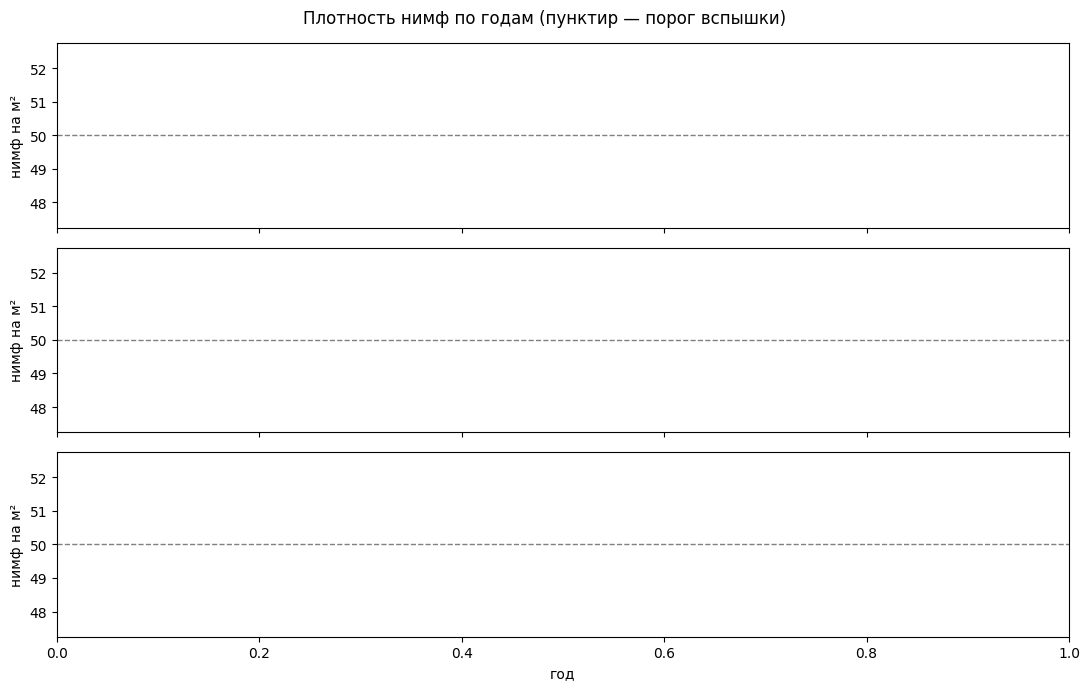

NameError: name 'is_prime' is not defined

In [85]:
import matplotlib.pyplot as plt

station_files = ['st02_chicago_il.txt', 'st07_atlanta_ga.txt', 'st01_springfield_il.txt']
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, sharey=True)   # три графика друг под другом
for k in range(3):
    ax = axes[k]
    # ваш код: прочитайте станцию station_files[k] через read_station
    # ваш код: ax.bar(годы, плотности, color='tab:green')
    ax.axhline(50, color='gray', linestyle='--', linewidth=1)
    # ваш код: ax.set_title(название, loc='left')
    ax.set_ylabel('нимф на м²')
axes[-1].set_xlabel('год')
fig.suptitle('Плотность нимф по годам (пунктир — порог вспышки)')
plt.tight_layout()
plt.show()

colors = ['tab:red' if is_prime(c) else 'tab:gray' for c in C.tolist()]
fig, ax = plt.subplots(figsize=(8, 3.5))
# ваш код: ax.bar(..., ..., color=colors)
ax.set_xticks(C)
ax.set_xlabel('период цикады C, лет')
ax.set_ylabel('неудачных лет за 1000')
ax.set_title('Совпадения с хищниками (P = 2..10); красные — простые C')
plt.show()

**Ответ:** *напишите здесь*

📝 **Задание 6.4 (3 балла).** **Насколько numpy быстрее?** Ниже готовая функция `bad_loop(n_years)` — ваш перебор из 5.3, обёрнутый в функцию. Напишите `bad_numpy(n_years)` — то же через `np.lcm.outer`, без циклов. Запустите сравнение и запишите вывод: во сколько раз быстрее numpy и как время каждого способа растёт с ростом числа лет.

📘 `time.perf_counter()` — текущее время в секундах (с высокой точностью); разность двух замеров — время работы кода между ними.

In [ ]:
import time

def bad_loop(n_years):
    result = []
    for C_ in range(10, 21):
        total_ = 0
        for P_ in range(2, 11):
            for year in range(1, n_years + 1):
                if year % C_ == 0 and year % P_ == 0:
                    total_ += 1
        result.append(total_)
    return result

In [ ]:
def bad_numpy(n_years):
    # ваш код
    pass

In [ ]:
for n in [1000, 10000, 30000]:
    t0 = time.perf_counter()
    r1 = bad_loop(n)
    t1 = time.perf_counter()
    r2 = bad_numpy(n)
    t2 = time.perf_counter()
    assert np.array_equal(r1, r2), 'результаты не совпали!'
    print(f'{n:>6} лет: перебор {t1 - t0:8.4f} с, numpy {t2 - t1:8.6f} с, '
          f'быстрее в {(t1 - t0) / (t2 - t1):,.0f} раз')

**Ответ:** *напишите здесь*

---
## Часть 7. Итоговый отчёт — 5 баллов

📝 **Задание 7.1 (5 баллов).**

а) Запишите таблицу станций в файл `results/stations.csv` со столбцами
`code,name,period,brood,first_emergence,last_emergence,max_density`. Для Спрингфилда впишите результат 5.1: период `13+17`, выводок `XIX+XIII`.

б) Запишите в `results/report.txt` короткий текстовый отчёт руководителю экспедиции: сколько станций обработано; какие выводки найдены (без повторов); где живут два выводка сразу; когда XIII и XIX встретятся снова; какой период лучший в модели 5.3 и как ведут себя простые периоды; какая запись архива ошибочна.

в) Выведите содержимое `report.txt` на экран.

In [ ]:
# а) ваш код: results/stations.csv

# б) ваш код: results/report.txt

# в) ваш код: вывести report.txt

Последняя проверка — снова командой bash: что лежит в `results/`?

In [ ]:
%%bash
ls -l results
echo '---'
cat results/stations.csv

### Выводы
Напишите 4–6 предложений. Что вы выяснили о цикадах? Подтверждает ли расчёт гипотезу о простых периодах? Каковы ограничения модели 5.3? Какие инструменты Python (файлы, списки, функции, numpy) оказались самыми полезными и почему?

**Выводы:** *напишите здесь*

---
## Бонусные задания (+15 баллов)

📝 **Б1 (3 балла). Обратный перевод.** Напишите `int_to_roman(n)` и проверьте, что `roman_to_int(int_to_roman(n)) == n` для всех `n` от 1 до 3999. Запишите годы 1803 и 2245 римскими цифрами (и добавьте их в отчёт).

Подсказка: удобно перебирать пары «значение — запись» от больших к меньшим: (1000, 'M'), (900, 'CM'), (500, 'D'), (400, 'CD'), …, (1, 'I').

In [ ]:
def int_to_roman(n):
    # ваш код
    pass

📝 **Б2 (4 балла). «Торопыги».** У 17-летних цикад бывает, что часть нимф выходит на **4 года раньше** основной вспышки. Для каждой станции с периодом 17 найдите годы, когда плотность была от 5 до 49 ровно за 4 года до вспышки. Выведите эти годы и долю вспышек, перед которыми были «торопыги». Есть ли такое у 13-летних станций? Можно списками, можно numpy.

In [ ]:
# ваш код

📝 **Б3 (5 баллов). Вторая гипотеза — гибридизация.** Есть и другое объяснение простых периодов. Если два выводка с разными периодами выходят одновременно, они могут скрещиваться, и потомство «сбивается» с ритма. Значит, выгодно, чтобы с выводками **других** периодов встречи были как можно реже.

Для каждого `C` от 10 до 20 найдите **минимальный** интервал между совместными выходами с выводком любого другого периода `C'` из 10..20 (это min по `C' ≠ C` от НОК(C, C')). У каких `C` этот минимальный интервал больше всего? Решите двумя способами: циклами и в numpy (`np.lcm.outer`, а диагональ `C' = C` нужно исключить — например, заменив её большим числом через `np.fill_diagonal`).

In [ ]:
# ваш код

📝 **Б4 (3 балла). Ещё немного bash.** 📘 `grep 'текст' файл` выводит строки файла, в которых есть `текст`. `grep -c 'текст' файлы` выводит, **сколько** таких строк в каждом файле.
а) Одним конвейером посчитайте, сколько всего пропусков `н/д` во всех журналах станций. Сверьте результат для Чикаго с заданием 2.1: не попадает ли в подсчёт что-то лишнее?
б) Одной командой `grep -c` выведите число пропусков по каждой станции.
в) Выведите все записи архива о выводке XIII — и только их. Сначала попробуйте `grep 'XIII'` и посмотрите, что лишнего он находит и почему.

In [ ]:
%%bash
# ваш код

---
**Готово!** Не забудьте: *Restart Kernel and Run All*, проверить, что ошибок нет, сохранить ноутбук как `Лаба1_Фамилия_Группа.ipynb` и сдать его вместе с папкой `results/`.